# Chapter 44: Asset Pricing Models, Factors, and Empirical Puzzles

This notebook reruns four worked examples from the chapter: the equity premium a consumption model can explain, a price that swings around a constant value, a losing gambler chasing break-even, and a size-value alpha after risk and trading costs. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def stacked_bar(ax, names, parts, part_labels, colors=None, ylabel="Value", total_marker=True, fmt=None):
    """Bars built from signed parts (one list per part), with a marker at each bar's net total.

    Positive parts stack upward from zero and negative parts downward, so a bar with a
    negative substitution part and a positive income part shows both pieces and the net.
    """
    parts = [[float(v) for v in p] for p in parts]
    n = len(names)
    xs = np.arange(n)
    colors = colors or [color(i) for i in range(len(parts))]
    pos_base, neg_base = np.zeros(n), np.zeros(n)
    for p, lab, col in zip(parts, part_labels, colors):
        p = np.array(p)
        base = np.where(p >= 0, pos_base, neg_base)
        ax.bar(xs, p, bottom=base, color=color(col), width=0.55, label=lab)
        pos_base = pos_base + np.where(p >= 0, p, 0)
        neg_base = neg_base + np.where(p < 0, p, 0)
    totals = np.sum(np.array(parts), axis=0)
    if total_marker:
        ax.scatter(xs, totals, marker="D", s=46, color=PALETTE["ink"], zorder=5)
        for x, t in zip(xs, totals):
            ax.annotate(f"net {fmt(t) if fmt else f'{t:,.2f}'}", (x, t), xytext=(14, 0), textcoords="offset points",
                        ha="left", va="center", fontsize=LABEL_SIZE,
                        bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(xs, names)
    ax.set_xlim(-0.6, n - 0.4 + 0.5)
    ax.set_ylabel(ylabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def signed(value, digits=2, comma=True):
    """Number for use inside a written sum: negatives get parentheses, '(-5.00)'."""
    text = num(value, digits, comma)
    return f"({text})" if text.startswith("-") else text


def capm(rf, beta, rm):
    """capital-asset-pricing-model: E[R_i] = R_f + beta_i (E[R_M] - R_f), in percent.

    Book (ch043): capm(2.5, 1.3, 8.5) = 10.3; capm(2.5, 0.8, 8.5) = 7.3; premium 6.
    """
    return rf + beta * (rm - rf)


def alpha(r, rf, beta, rm):
    """CAPM alpha: realized return minus R_f + beta (R_M - R_f) (size-and-value-effects).

    Book: chapter 44, portfolio S earns 0.11 against a CAPM 0.08, alpha 0.03.
    """
    return r - capm(rf, beta, rm)


def sdf_two_state(beta, gamma, growth, probs=None):
    """Stochastic discount factor m = beta (C_{t+1}/C_t)^(-gamma) in each state (equity-premium-puzzle).

    ``growth`` lists consumption growth rates by state. Book: chapter 44, beta 1, gamma 2,
    growth 0.02 and 0: m = 0.96117 and 1. ``probs`` is accepted for symmetry and unused.
    """
    return [beta * (1 + g) ** (-gamma) for g in growth]


def implied_premium(m, R, probs):
    """Model-implied equity premium -Cov(m, R)/E[m] and related moments (equity-premium-puzzle).

    Returns E[m], R^f = 1/E[m], E[R], Cov(m, R), the premium, E[mR], the common shift x that
    makes E[m(R + x)] = 1, the shifted returns and their mean. Book: chapter 44, R^f 1.01980,
    Cov -0.004466, premium 0.004554, E[mR] 1.04476, model-consistent pair 1.25435 and 0.79435
    (mean 1.02435).
    """
    em = sum(p * x for p, x in zip(probs, m))
    er = sum(p * r for p, r in zip(probs, R))
    emr = sum(p * x * r for p, x, r in zip(probs, m, R))
    cov = emr - em * er
    shift = (1 - emr) / em
    shifted = [r + shift for r in R]
    return {"Em": em, "Rf": 1 / em, "ER": er, "cov": cov, "premium": -cov / em, "EmR": emr,
            "shift": shift, "shifted": shifted, "shifted_mean": er + shift}


def perpetuity_value(d, r):
    """Value of a constant perpetuity d / r (excess-volatility-puzzle). Book: 5 / 0.05 = 100."""
    return d / r


def implied_yield(d, p):
    """Required return that makes a perpetuity of d worth p: d / p (excess-volatility-puzzle).

    Book: chapter 44, 5/70 = 7.14% and 5/130 = 3.85%.
    """
    return d / p


plt.rcParams.update(HOUSE_RC)


finance = SimpleNamespace(capm=capm, alpha=alpha, sdf_two_state=sdf_two_state, implied_premium=implied_premium, perpetuity_value=perpetuity_value, implied_yield=implied_yield)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'equity-premium-puzzle': {'g_good': 0.02,
                           'g_bad': 0.0,
                           'p': 0.5,
                           'R_good': 1.3,
                           'R_bad': 0.84,
                           'mean_R': 1.07,
                           'safe': 1.02,
                           'observed_premium_points': 5,
                           'beta': 1,
                           'gamma': 2,
                           'm_good': 0.96117,
                           'm_bad': 1,
                           'Rf': 1.0198,
                           'cov': -0.004466,
                           'premium': 0.004554,
                           'premium_points': 0.46,
                           'EmR': 1.04476,
                           'state_return_gap': 0.46,
                           'consistent_good': 1.25435,
                           'consistent_bad': 0.79435,
                           'consistent_mean': 1.02435,
                           'consistent_excess_points': 0.4554,
                           'unexplained_points': 4.54},
 'excess-volatility-puzzle': {'d': 5,
                              'r': 0.05,
                              'P_star': 100,
                              'low': 70,
                              'high': 130,
                              'variance': 900,
                              'r_low_pct': 7.14,
                              'r_high_pct': 3.85},
 'break-even-effect': {'win': 60,
                       'loss': -70,
                       'p': 0.5,
                       'lam': 2,
                       'ev': -5,
                       'standalone': -4.49,
                       'L': -60,
                       'stop': -15.49,
                       'gamble': -11.4,
                       'final_gamble': -65,
                       'final_stop': -60},
 'size-and-value-effects': {'rf': 2,
                            'premium': 6,
                            'beta': 1.0,
                            'capm': 8,
                            'S': 11,
                            'B': 8,
                            'spread': 3,
                            'alpha': 3,
                            'cost': 4,
                            'net': -1},
 'constructed': {'equity-premium-puzzle': {'gamma': [5, 10, 25], 'g_good': [0.01, 0.04]},
                 'excess-volatility-puzzle': {'swing': [0, 15, 45]},
                 'break-even-effect': {'L': [-30, -90], 'win': [40, 80]},
                 'size-and-value-effects': {'cost': [0, 2], 'beta': [0.8, 1.2, 1.5]}}}


def pp(x, digits=2):
    """A gross-return difference in percentage points: 0.004554 -> '0.46'."""
    return num(100 * x, digits)


def premium_picture(gamma=2, g=0.02):
    bv = BV["equity-premium-puzzle"]
    R = [bv["R_good"], bv["R_bad"]]
    probs = [0.5, 0.5]
    m = finance.sdf_two_state(1, gamma, [g, 0.0])
    res = finance.implied_premium(m, R, probs)
    observed = bv["observed_premium_points"]
    model_pp = 100 * res["premium"]
    gap = observed - model_pp
    fig, (ax, ax2) = new_figure(ncols=2)
    bar_compare(ax, ["Model premium", "Stipulated premium"], [model_pp, observed], colors=["teal", "gold"],
                value_labels=[f"{num(model_pp)} points", f"{num(observed)} points"],
                ylabel="Equity premium (percentage points)", xlabel="Source of the premium")
    top = max(model_pp, observed)
    ax.set_ylim(0, top * 1.22)
    bar_compare(ax2, ["Good state", "Bad state"], m, colors=["navy", "grey"],
                value_labels=[num(m[0], 5), num(m[1], 5)], ylabel="Discount factor m", xlabel="Consumption state")
    ax2.set_ylim(0, 1.25)
    hline(ax2, res["Em"], col="terracotta")
    ax2.text(0.5, 0.08, f"dashed line: E[m] = {num(res['Em'], 5)}", transform=ax2.transAxes, ha="center",
             fontsize=10.5, color=PALETTE["terracotta"],
             bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    if gap > 0:
        gap_text = f"{num(gap)} points of the stipulated premium remain unexplained"
        gap_metric = num(gap)
    else:
        gap_text = f"the model premium exceeds the stipulated 5 points by {num(-gap)} points"
        gap_metric = f"none (model exceeds by {num(-gap)})"
    metrics = {"m in good state": num(m[0], 5), "Model safe return R^f": num(res["Rf"], 5),
               "Cov(m, R^e)": num(res["cov"], 6), "Model premium (points)": num(model_pp),
               "E[m R^e]": num(res["EmR"], 5), "Unexplained (points)": gap_metric}
    s = res["shifted"]
    interp = (f"m in the good state = (1 + {num(g, 2)})^(-{gamma}) = {num(m[0], 5)} and 1 in the bad state, so "
              f"E[m] = {num(res['Em'], 5)} and R^f = 1 / {num(res['Em'], 5)} = {num(res['Rf'], 5)}. "
              f"E[m R^e] = 0.5 x {num(m[0], 5)} x 1.30 + 0.5 x 1 x 0.84 = {num(res['EmR'], 5)}, and "
              f"Cov(m, R^e) = {num(res['EmR'], 6)} - {num(res['Em'], 6)} x 1.07 = {num(res['cov'], 6)}. "
              f"The model premium is {num(-res['cov'], 6)} / {num(res['Em'], 6)} = {num(res['premium'], 6)}, or "
              f"{num(model_pp)} percentage points, so {gap_text}. Keeping the state return gap of 0.46 "
              f"(1.30 minus 0.84, a gross return gap, not the premium), the model-consistent returns are "
              f"{num(s[0], 5)} and {num(s[1], 5)}.")
    steps = [f"m good = (1 + {num(g, 2)})^(-{gamma}) = {num(m[0], 5)}; m bad = 1",
             f"E[m] = 0.5 x {num(m[0], 5)} + 0.5 x 1 = {num(res['Em'], 5)}; R^f = 1 / {num(res['Em'], 5)} = {num(res['Rf'], 5)}",
             f"E[m R^e] = 0.5 x {num(m[0], 5)} x 1.30 + 0.5 x 0.84 = {num(res['EmR'], 5)}",
             f"Cov(m, R^e) = {num(res['EmR'], 6)} - {num(res['Em'], 6)} x 1.07 = {num(res['cov'], 6)}",
             f"Premium = {num(-res['cov'], 6)} / {num(res['Em'], 6)} = {num(res['premium'], 6)}, {num(model_pp)} points",
             f"Stipulated 5 - model {num(model_pp)} = {num(gap)} points"]
    alt = (f"Left: bars for the model premium, {num(model_pp)} points, and the stipulated premium, 5 points, with "
           f"risk aversion {gamma} and good-state growth {num(100 * g, 0)} percent. Right: the discount factor is "
           f"{num(m[0], 5)} in the good state and 1 in the bad state.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def volatility_picture(swing=30, mode="constant"):
    bv = BV["excess-volatility-puzzle"]
    d, r = bv["d"], bv["r"]
    p_star = finance.perpetuity_value(d, r)
    lo, hi = p_star - swing, p_star + swing
    var = ((lo - p_star) ** 2 + (hi - p_star) ** 2) / 2
    r_lo, r_hi = finance.implied_yield(d, lo), finance.implied_yield(d, hi)
    fig, ax = new_figure()
    xs = [0, 1]
    ax.bar(xs, [lo, hi], color=[PALETTE["navy"], PALETTE["teal"]], width=0.55)
    ax.set_xticks(xs, ["Sentiment state 1", "Sentiment state 2"])
    hline(ax, p_star, f"P* = {money(p_star, 0)}", col="terracotta", x_frac=0.78)
    for x, p, rr in zip(xs, [lo, hi], [r_lo, r_hi]):
        text = money(p, 0) if mode == "constant" else f"{money(p, 0)}, needs r = {num(100 * rr)}%"
        label(ax, x, p, text, col="ink", dx=0, dy=4, ha="center")
    ax.set_ylim(0, 190)
    ax.set_xlim(-0.6, 2.3)
    ax.set_ylabel(tex_safe("Price ($)"))
    ax.set_xlabel("Equally likely sentiment state")
    consistent = mode == "varies" or swing == 0
    metrics = {"P* = 5 / 0.05": money(p_star), "Price variance": num(var), "Variance of P*": num(0),
               "Required return, state 1": f"{num(100 * r_lo)}%", "Required return, state 2": f"{num(100 * r_hi)}%",
               "Prices consistent with the model": "yes" if consistent else "no"}
    base = (f"P* = 5 / 0.05 = {money(p_star, 0)} in both states. Price variance = (({num(lo, 0)} - 100)^2 + "
            f"({num(hi, 0)} - 100)^2) / 2 = {num(var)}, against zero for P*.")
    if swing == 0:
        tail = " With no swing both prices equal P*, so prices and value agree at the constant 5 percent rate."
    elif mode == "constant":
        tail = (" With a constant 5 percent rate a known 5 dollar stream cannot be worth both "
                f"{money(lo, 0)} and {money(hi, 0)}, so the prices violate the benchmark.")
    else:
        tail = (f" If the required return may vary, 5 / {num(lo, 0)} = {num(100 * r_lo)}% and 5 / {num(hi, 0)} = "
                f"{num(100 * r_hi)}% make both prices present-value consistent; whether such rate moves are "
                f"justified is a separate question.")
    interp = base + tail
    steps = [f"P* = 5 / 0.05 = {num(p_star)}",
             f"Price variance = (({num(lo, 0)} - 100)^2 + ({num(hi, 0)} - 100)^2) / 2 = {num(var)}",
             f"Required return in state 1 = 5 / {num(lo, 0)} = {num(100 * r_lo)}%",
             f"Required return in state 2 = 5 / {num(hi, 0)} = {num(100 * r_hi)}%"]
    alt = (f"Two price bars, {money(lo, 0)} and {money(hi, 0)}, against a flat line at P* = {money(p_star, 0)}. "
           + ("The labels show the required returns that would justify each price." if mode == "varies"
              else "The discount rate is held at 5 percent."))
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def value_sqrt(z, lam=2):
    """The book's illustrative value function: sqrt(z) for gains, -lam sqrt(-z) for losses."""
    return math.sqrt(z) if z >= 0 else -lam * math.sqrt(-z)


def gamble_score(L, outcomes, probs, lam=2):
    """Score of a gamble integrated with a prior result L: sum of p_i v(L + x_i)."""
    return sum(p * value_sqrt(L + x, lam) for p, x in zip(probs, outcomes))


def breakeven_picture(prior=-60, win=60):
    L = prior
    loss = BV["break-even-effect"]["loss"]
    stop = value_sqrt(L)
    gamble = gamble_score(L, [win, loss], [0.5, 0.5])
    up, down = L + win, L + loss
    final_g = L + 0.5 * win + 0.5 * loss
    fig, (ax, ax2) = new_figure(ncols=2)
    zs = np.linspace(-170, 90, 400)
    ax.plot(zs, [value_sqrt(z) for z in zs], color=PALETTE["navy"], linewidth=2.2)
    ax.axhline(0, color=PALETTE["grey"], linewidth=0.8)
    ax.axvline(0, color=PALETTE["grey"], linewidth=0.8)
    mark(ax, L, stop, f"stop {num(L, 0)}", col="gold", dx=8, dy=-10, va="top")
    mark(ax, up, value_sqrt(up), f"win {num(up, 0)}", col="teal", dx=-8, dy=8, ha="right")
    mark(ax, down, value_sqrt(down), f"lose {num(down, 0)}", col="terracotta", dx=8, dy=0)
    ax.set_xlim(-170, 90)
    ax.set_ylim(-28, 12)
    ax.set_xlabel(tex_safe("Final position z ($)"))
    ax.set_ylabel("Value v(z)")
    bar_compare(ax2, ["Stop", "Gamble"], [stop, gamble], colors=["gold", "teal"],
                value_labels=[num(stop), num(gamble)], ylabel="Score", xlabel="Choice after the prior loss")
    ax2.set_ylim(-28, 6)
    if abs(gamble - stop) < 1e-9:
        verdict = "The two scores tie."
        choice = "tie"
    elif gamble > stop:
        verdict = "The gamble scores higher, so it is taken."
        choice = "gamble"
    else:
        verdict = "Stopping scores higher, so the gamble is rejected."
        choice = "stop"
    ev = 0.5 * win + 0.5 * loss
    metrics = {"Stop value v(L)": num(stop), "Gamble score": num(gamble), "Choice": choice,
               "Expected value of the wager": money(ev), "Expected final position, gamble": money(final_g),
               "Final position, stop": money(L)}
    v_up = "sqrt" if up >= 0 else "-2 sqrt"
    interp = (f"Stopping is worth v({num(L, 0)}) = {num(stop)}. The gamble ends at {num(up, 0)} or {num(down, 0)}, so its "
              f"score is 0.5 x {signed(value_sqrt(up), 3)} + 0.5 x {signed(value_sqrt(down), 3)} = {num(gamble)}. {verdict} "
              f"The wager's expected value is 0.5 x {num(win, 0)} + 0.5 x ({num(loss, 0)}) = {num(ev)}, so the expected "
              f"final position is {num(final_g)} against {num(L, 0)} from stopping.")
    steps = [f"v({num(L, 0)}) = {'0' if L == 0 else f'-2 sqrt({num(-L, 0)})'} = {num(stop)}",
             f"v({num(up, 0)}) = {v_up}({num(abs(up), 0)}) = {num(value_sqrt(up), 3)}",
             f"v({num(down, 0)}) = -2 sqrt({num(-down, 0)}) = {num(value_sqrt(down), 3)}",
             f"Gamble score = 0.5 x {signed(value_sqrt(up), 3)} + 0.5 x {signed(value_sqrt(down), 3)} = {num(gamble)}",
             f"Expected final position = {num(L, 0)} + {num(ev)} = {num(final_g)}"]
    alt = (f"Left: the S-shaped value function with points for stopping at {num(L, 0)}, winning to {num(up, 0)} and "
           f"losing to {num(down, 0)}. Right: bars for the stop value {num(stop)} and the gamble score {num(gamble)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def alpha_picture(cost=4, beta=1.0):
    bv = BV["size-and-value-effects"]
    rf, prem, r_s = bv["rf"], bv["premium"], bv["S"]
    rm = rf + prem
    req = finance.capm(rf, beta, rm)
    a = finance.alpha(r_s, rf, beta, rm)
    net = a - cost
    fig, ax = new_figure()
    stacked_bar(ax, ["CAPM prediction", "Gross alpha", "Costs", "Net alpha"],
                [[req, 0, 0, 0], [0, a, 0, 0], [0, 0, -cost, 0], [0, 0, 0, net]],
                ["CAPM", "alpha", "costs", "net"], colors=["navy", "teal", "terracotta", "gold"],
                ylabel="Percent per period", total_marker=False)
    ax.set_xlabel("Return attribution for portfolio S")
    for x, v in enumerate([req, a, -cost, net]):
        label(ax, x, v, f"{num(v, 1)}%", dx=0, dy=4 if v >= 0 else -4, ha="center", va="bottom" if v >= 0 else "top")
    ax.set_ylim(-6, 12)
    ax.set_xlim(-0.6, 3.6)
    sign = "positive" if a > 1e-9 else ("zero" if abs(a) <= 1e-9 else "negative")
    if abs(net) < 1e-9 and cost == 0:
        nv = "With zero gross alpha and no costs, net alpha is zero."
    elif abs(net) < 1e-9:
        nv = "Costs exactly use up the alpha: net alpha is zero."
    elif net > 0:
        nv = "After costs a positive net alpha remains."
    else:
        nv = "After costs the implementer loses relative to CAPM."
    metrics = {"CAPM required return": f"{num(req, 1)}%", "S return": f"{num(r_s, 1)}%",
               "S minus B spread": f"{num(r_s - bv['B'], 1)}%", "Gross alpha": f"{num(a, 1)}%",
               "Costs": f"{num(cost, 1)}%", "Net alpha": f"{num(net, 1)}%"}
    interp = (f"CAPM requires 2% + {num(beta, 1)} x 6% = {num(req, 1)}%. Portfolio S earns 11%, so gross alpha is "
              f"11% - {num(req, 1)}% = {num(a, 1)}%, which is {sign}. Net of {num(cost, 1)}% in costs, alpha is "
              f"{num(a, 1)}% - {num(cost, 1)}% = {num(net, 1)}%. {nv} The raw S minus B spread stays 11% - 8% = 3%.")
    steps = [f"CAPM = 2 + {num(beta, 1)} x 6 = {num(req, 1)}%",
             f"Gross alpha = 11 - {num(req, 1)} = {num(a, 1)}%",
             f"Net alpha = {num(a, 1)} - {num(cost, 1)} = {num(net, 1)}%"]
    alt = (f"Bars for the CAPM prediction {num(req, 1)}%, gross alpha {num(a, 1)}%, costs of {num(cost, 1)}% shown "
           f"below zero, and net alpha {num(net, 1)}%, with beta {num(beta, 1)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Equity-premium puzzle: how big a premium does consumption risk justify?

Consumption grows 2 percent in a good state and 0 in a bad state, with probability one half each. Equity returns 1.30 or 0.84 and the safe return is 1.02, a 5 point premium. With $\beta=1$ and $\gamma=2$:

$$m_{t+1}=\beta\left(\frac{C_{t+1}}{C_t}\right)^{-\gamma}.$$

$$R^f=\frac{1}{\mathbb{E}[m]}\approx1.01980, \qquad -\frac{\operatorname{Cov}(m,R^e)}{\mathbb{E}[m]}\approx0.004554$$

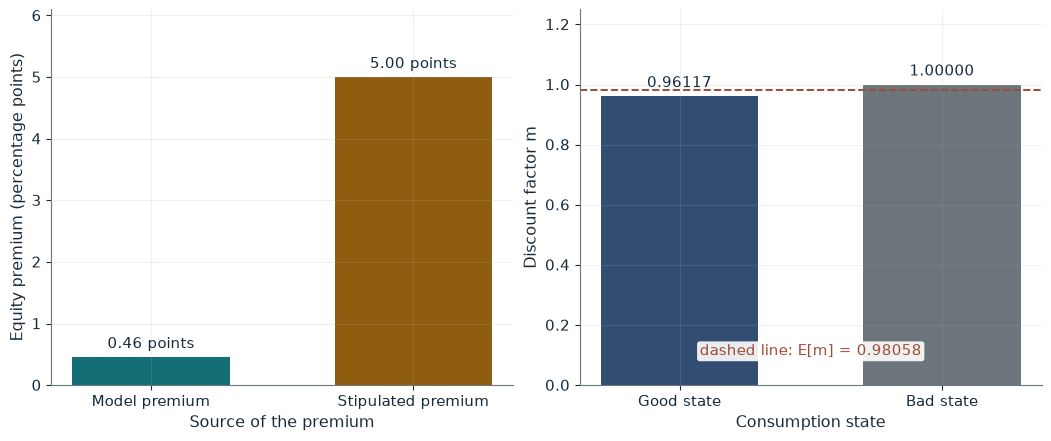

m in good state         0.96117
Model safe return R^f   1.01980
Cov(m, R^e)             -0.004466
Model premium (points)  0.46
E[m R^e]                1.04476
Unexplained (points)    4.54

Worked steps:
  1. m good = (1 + 0.02)^(-2) = 0.96117; m bad = 1
  2. E[m] = 0.5 x 0.96117 + 0.5 x 1 = 0.98058; R^f = 1 / 0.98058 = 1.01980
  3. E[m R^e] = 0.5 x 0.96117 x 1.30 + 0.5 x 0.84 = 1.04476
  4. Cov(m, R^e) = 1.044760 - 0.980584 x 1.07 = -0.004466
  5. Premium = 0.004466 / 0.980584 = 0.004554, 0.46 points
  6. Stipulated 5 - model 0.46 = 4.54 points

m in the good state = (1 + 0.02)^(-2) = 0.96117 and 1 in the bad state, so E[m] = 0.98058 and R^f = 1 / 0.98058 = 1.01980. E[m R^e] = 0.5 x 0.96117 x 1.30 + 0.5 x 1 x 0.84 = 1.04476, and Cov(m, R^e) = 1.044760 - 0.980584 x 1.07 = -0.004466. The model premium is 0.004466 / 0.980584 = 0.004554, or 0.46 percentage points, so 4.54 points of the stipulated premium remain unexplained. Keeping the state return gap of 0.46 (1.30 minus 0.84, a gross ret

In [2]:
show(premium_picture(gamma=2, g=0.02))

Change one input, `gamma`, and hold the others at the book's values:

In [3]:
sweep(premium_picture, 'gamma', [2, 5, 10, 25], {'g': 0.02}, ['m in good state', 'Model safe return R^f', 'Model premium (points)', 'Unexplained (points)'])

gamma | m in good state | Model safe return R^f | Model premium (points) | Unexplained (points)
2 | 0.96117 | 1.01980 | 0.46 | 4.54
5 | 0.90573 | 1.04947 | 1.14 | 3.86
10 | 0.82035 | 1.09869 | 2.27 | 2.73
25 | 0.60953 | 1.24260 | 5.58 | none (model exceeds by 0.58)


At $\gamma=2$ the model explains 0.46 percentage point of the 5 point premium, leaving 4.54. This 0.46 is a premium in percentage points; the 0.46 gap between the state returns 1.30 and 0.84 is a different quantity that happens to share the digits. Only $\gamma$ near 25 closes the gap, and it pushes the model safe return to 1.24.

## 2. Excess-volatility puzzle: prices that move more than value

A share pays 5 dollars forever and the discount rate is 5 percent.

$$P^*=\frac{5}{0.05}=100\text{ dollars}.$$

Two equally likely sentiment states quote 70 and 130 dollars:

$$\frac{(70-100)^2+(130-100)^2}{2}=900.$$

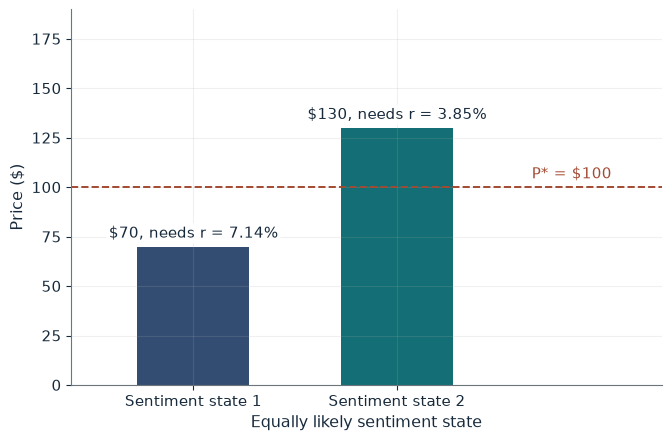

P* = 5 / 0.05                     $100.00
Price variance                    900.00
Variance of P*                    0.00
Required return, state 1          7.14%
Required return, state 2          3.85%
Prices consistent with the model  yes

Worked steps:
  1. P* = 5 / 0.05 = 100.00
  2. Price variance = ((70 - 100)^2 + (130 - 100)^2) / 2 = 900.00
  3. Required return in state 1 = 5 / 70 = 7.14%
  4. Required return in state 2 = 5 / 130 = 3.85%

P* = 5 / 0.05 = $100 in both states. Price variance = ((70 - 100)^2 + (130 - 100)^2) / 2 = 900.00, against zero for P*. If the required return may vary, 5 / 70 = 7.14% and 5 / 130 = 3.85% make both prices present-value consistent; whether such rate moves are justified is a separate question.


In [4]:
show(volatility_picture(swing=30, mode='varies'))

Change one input, `swing`, and hold the others at the book's values:

In [5]:
sweep(volatility_picture, 'swing', [0, 15, 30, 45], {'mode': 'constant'}, ['Price variance', 'Required return, state 1', 'Required return, state 2'])

swing | Price variance | Required return, state 1 | Required return, state 2
0 | 0.00 | 5.00% | 5.00%
15 | 225.00 | 5.88% | 4.35%
30 | 900.00 | 7.14% | 3.85%
45 | 2,025.00 | 9.09% | 3.45%


With a constant rate the price variance of 900 cannot come from value, whose variance is zero. Required returns of 7.14% and 3.85% would make 70 and 130 consistent, so the test depends on the constant-rate assumption.

## 3. Break-even effect: chasing break-even

A wager pays +60 or -70 dollars with probability one half. The value function is $\sqrt{z}$ for gains and $-2\sqrt{-z}$ for losses. After a 60 dollar loss:

$$v(-60)=-2\sqrt{60}\approx-15.49. \qquad 0.5v(0)+0.5v(-130)\approx-11.40.$$

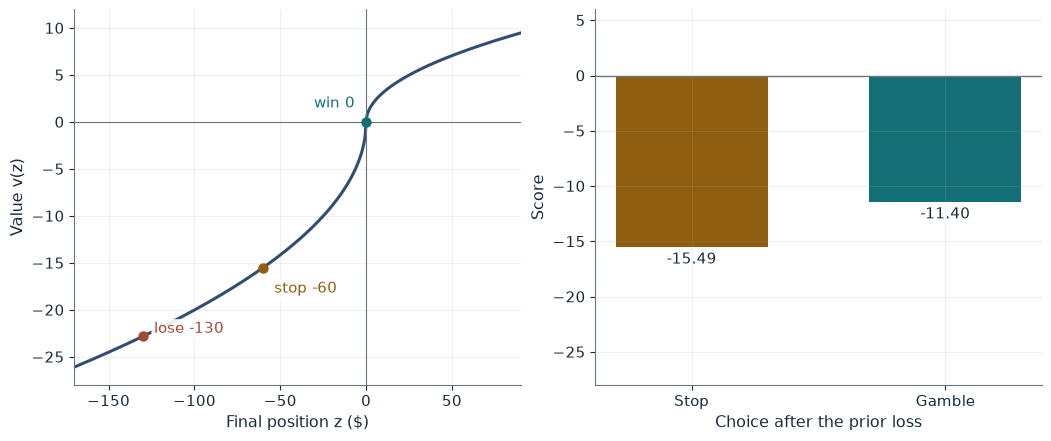

Stop value v(L)                  -15.49
Gamble score                     -11.40
Choice                           gamble
Expected value of the wager      -$5.00
Expected final position, gamble  -$65.00
Final position, stop             -$60.00

Worked steps:
  1. v(-60) = -2 sqrt(60) = -15.49
  2. v(0) = sqrt(0) = 0.000
  3. v(-130) = -2 sqrt(130) = -22.804
  4. Gamble score = 0.5 x 0.000 + 0.5 x (-22.804) = -11.40
  5. Expected final position = -60 + -5.00 = -65.00

Stopping is worth v(-60) = -15.49. The gamble ends at 0 or -130, so its score is 0.5 x 0.000 + 0.5 x (-22.804) = -11.40. The gamble scores higher, so it is taken. The wager's expected value is 0.5 x 60 + 0.5 x (-70) = -5.00, so the expected final position is -65.00 against -60 from stopping.


In [6]:
show(breakeven_picture(prior=-60, win=60))

Change one input, `prior`, and hold the others at the book's values:

In [7]:
sweep(breakeven_picture, 'prior', [0, -30, -60, -90], {'win': 60}, ['Stop value v(L)', 'Gamble score', 'Choice'])

prior | Stop value v(L) | Gamble score | Choice
0 | 0.00 | -4.49 | stop
-30 | -10.95 | -7.26 | gamble
-60 | -15.49 | -11.40 | gamble
-90 | -18.97 | -18.13 | gamble


At the start the gamble scores -4.49 and is rejected. After the 60 dollar loss it scores -11.40, above -15.49 for stopping, although its expected final position (-65) is worse than -60.

## 4. Size and value effects: alpha after costs

Safe return 2%, market premium 6%, beta 1.0. Portfolio S earns 11% and B earns 8%.

$$R_f+\beta(R_M-R_f)=2\%+1.0(6\%)=8\%$$

$$11\%-8\%=3\%. \qquad 3\%-4\%=-1\%.$$

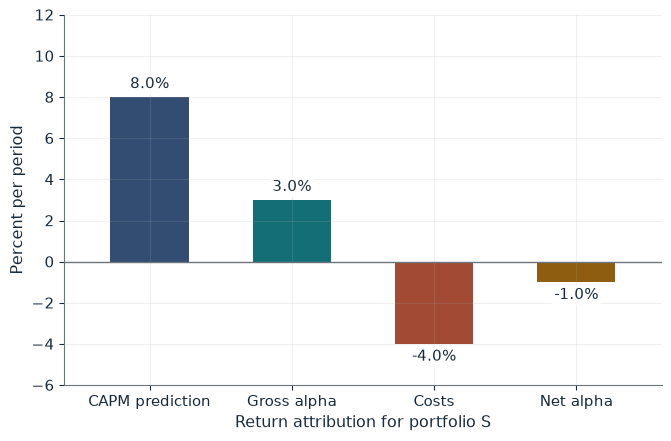

CAPM required return  8.0%
S return              11.0%
S minus B spread      3.0%
Gross alpha           3.0%
Costs                 4.0%
Net alpha             -1.0%

Worked steps:
  1. CAPM = 2 + 1.0 x 6 = 8.0%
  2. Gross alpha = 11 - 8.0 = 3.0%
  3. Net alpha = 3.0 - 4.0 = -1.0%

CAPM requires 2% + 1.0 x 6% = 8.0%. Portfolio S earns 11%, so gross alpha is 11% - 8.0% = 3.0%, which is positive. Net of 4.0% in costs, alpha is 3.0% - 4.0% = -1.0%. After costs the implementer loses relative to CAPM. The raw S minus B spread stays 11% - 8% = 3%.


In [8]:
show(alpha_picture(cost=4, beta=1.0))

Change one input, `beta`, and hold the others at the book's values:

In [9]:
sweep(alpha_picture, 'beta', [0.8, 1.0, 1.2, 1.5], {'cost': 4}, ['CAPM required return', 'Gross alpha', 'Net alpha'])

beta | CAPM required return | Gross alpha | Net alpha
0.8 | 6.8% | 4.2% | 0.2%
1.0 | 8.0% | 3.0% | -1.0%
1.2 | 9.2% | 1.8% | -2.2%
1.5 | 11.0% | 0.0% | -4.0%


The 3% gross alpha becomes -1% after 4% of costs. At beta 1.5 CAPM requires 11% and gross alpha is exactly zero.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

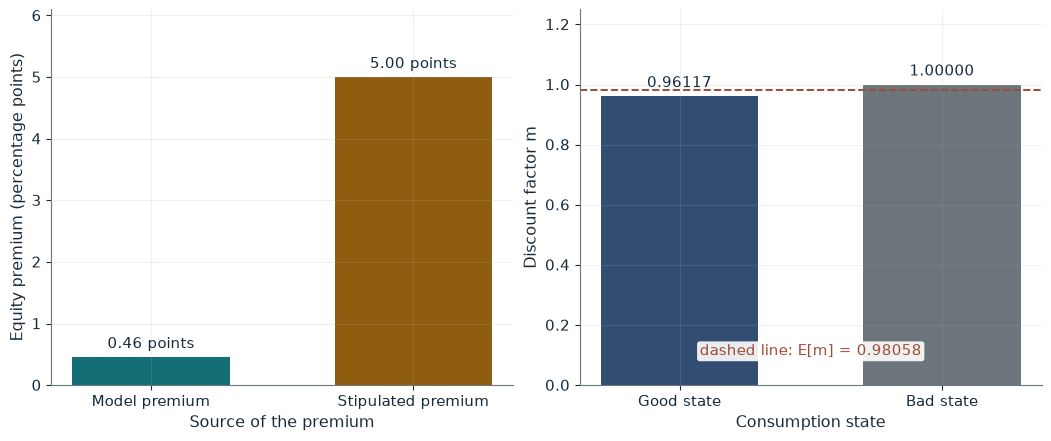

m in good state         0.96117
Model safe return R^f   1.01980
Cov(m, R^e)             -0.004466
Model premium (points)  0.46
E[m R^e]                1.04476
Unexplained (points)    4.54

Worked steps:
  1. m good = (1 + 0.02)^(-2) = 0.96117; m bad = 1
  2. E[m] = 0.5 x 0.96117 + 0.5 x 1 = 0.98058; R^f = 1 / 0.98058 = 1.01980
  3. E[m R^e] = 0.5 x 0.96117 x 1.30 + 0.5 x 0.84 = 1.04476
  4. Cov(m, R^e) = 1.044760 - 0.980584 x 1.07 = -0.004466
  5. Premium = 0.004466 / 0.980584 = 0.004554, 0.46 points
  6. Stipulated 5 - model 0.46 = 4.54 points

m in the good state = (1 + 0.02)^(-2) = 0.96117 and 1 in the bad state, so E[m] = 0.98058 and R^f = 1 / 0.98058 = 1.01980. E[m R^e] = 0.5 x 0.96117 x 1.30 + 0.5 x 1 x 0.84 = 1.04476, and Cov(m, R^e) = 1.044760 - 0.980584 x 1.07 = -0.004466. The model premium is 0.004466 / 0.980584 = 0.004554, or 0.46 percentage points, so 4.54 points of the stipulated premium remain unexplained. Keeping the state return gap of 0.46 (1.30 minus 0.84, a gross ret

In [10]:
show(premium_picture(gamma=2, g=0.02))

## Practice

**1.** At $\gamma=2$, what is the model-consistent mean equity return holding the 0.46 state return gap?

<details><summary>Answer</summary>

Shift both returns by x with E[m(R + x)] = 1: x = (1 - 1.04476) / 0.98058 = -0.04565, giving 1.25435 and 0.79435, mean 1.02435, which is 0.4554 point above 1.01980.

</details>

**2.** What required return makes a 5 dollar perpetuity worth 85 dollars?

<details><summary>Answer</summary>

5 / 85 = 5.88%.

</details>

**3.** With beta 1.2 and costs of 2%, what is the net alpha of portfolio S?

<details><summary>Answer</summary>

CAPM = 2 + 1.2 x 6 = 9.2%; alpha = 11 - 9.2 = 1.8%; net = 1.8 - 2 = -0.2%.

</details>